In [46]:
import pandas as pd
import numpy as np
import h5py
import scipy
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt
import tensorflow as tf
import torch
from torchvision import datasets, transforms
import torch.nn as nn
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch.optim as optim


In [47]:
# Transformaciones que se aplicarán a cada imagen
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.Grayscale(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Carga el dataset completo
full_dataset = datasets.ImageFolder('Training', transform=transform)

# Define el tamaño del conjunto de prueba
test_size = int(0.2 * len(full_dataset))
train_size = len(full_dataset) - test_size

# Divide el dataset en entrenamiento y prueba
train_dataset, test_dataset = random_split(full_dataset, [train_size, test_size])

# Creamos DataLoader para entrenamiento y prueba
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

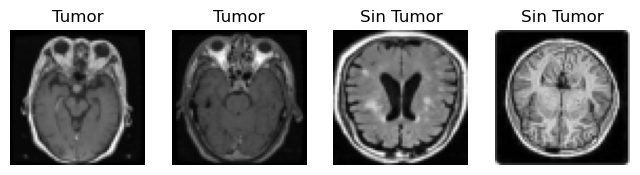

In [48]:
# Función para desnormalizar las imágenes
def imshow(img):
    img = img / 2 + 0.5  # desnormalizar
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)), cmap='gray')

# Encontrar imágenes con y sin tumores
def get_images(num_images=2, class_label=1):
    images = []
    for data, targets in train_loader:
        for i, target in enumerate(targets):
            if target == class_label and len(images) < num_images:
                images.append(data[i])
            if len(images) == num_images:
                return images

tumor_images = get_images(num_images=2, class_label=1)  # Imágenes de tumores
non_tumor_images = get_images(num_images=2, class_label=0)  # Imágenes sin tumores

# Mostrar las imágenes
plt.figure(figsize=(8, 4))
for i, img in enumerate(tumor_images + non_tumor_images):
    plt.subplot(1, 4, i + 1)
    imshow(img)
    plt.title("Tumor" if i < 2 else "Sin Tumor")
    plt.axis('off')
plt.show()


In [49]:
import torch
from collections import Counter

def check_binary_labels(loader):
    """ Verifica si las etiquetas en un DataLoader de PyTorch son binarias (0 o 1) y cuenta ellas.
    
    Args:
        loader (torch.utils.data.DataLoader): El DataLoader que contiene el dataset.
    
    Returns:
        tuple: (is_binary, num_zeros, num_ones) donde `is_binary` es un booleano indicando si las etiquetas son binarias,
               `num_zeros` es el número de etiquetas 0, y `num_ones` es el número de etiquetas 1.
    """
    label_list = []
    
    # Iterar sobre el DataLoader para obtener todas las etiquetas
    for _, labels in loader:
        if isinstance(labels, torch.Tensor):
            labels = labels.tolist()  # Convertir Tensor a lista si es necesario
        label_list.extend(labels)
    
    # Contar las etiquetas
    count = Counter(label_list)
    
    # Verificar si solo contienen 0 y 1
    is_binary = set(count.keys()).issubset({0, 1})
    
    # Obtener el número de ceros y unos
    num_zeros = count.get(0, 0)
    num_ones = count.get(1, 0)
    
    return is_binary, num_zeros, num_ones

# Ejemplo de uso:
# Supongamos que tienes `train_loader` y `test_loader` definidos como en tu código de carga de datos
is_binary, num_zeros, num_ones = check_binary_labels(train_loader)
print(f"Are labels binary? {is_binary}")
print(f"Number of 0s: {num_zeros}")
print(f"Number of 1s: {num_ones}")

# Ejemplo de uso:
# Supongamos que tienes `train_loader` y `test_loader` definidos como en tu código de carga de datos
is_binary, num_zeros, num_ones = check_binary_labels(test_loader)
print(f"Are labels binary? {is_binary}")
print(f"Number of 0s: {num_zeros}")
print(f"Number of 1s: {num_ones}")


Are labels binary? True
Number of 0s: 1605
Number of 1s: 4014
Are labels binary? True
Number of 0s: 395
Number of 1s: 1009


In [50]:
# Definición del modelo
class SimpleNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)  # Primera capa lineal
        self.relu = nn.ReLU()  # Función de activación ReLU para la capa oculta
        self.fc2 = nn.Linear(hidden_size, num_classes)  # Segunda capa lineal
        # Asegúrate de que num_classes sea 1 si usas sigmoid para clasificación binaria
        self.sigmoid = nn.Sigmoid()  # Función de activación sigmoide para la salida

    def forward(self, x):
        x = self.fc1(x)  # Pase hacia adelante a través de la primera capa lineal
        x = self.relu(x)  # Aplicación de la función ReLU
        x = self.fc2(x)  # Pase hacia adelante a través de la segunda capa lineal
        x = self.sigmoid(x)  # Aplicación de la función sigmoide
        return x

In [51]:
# Tamaño de la entrada de la red (tamaño de la imagen después de aplanarla)
input_size = 64 * 64 
hidden_size = 128
num_classes = 1

In [52]:
# Inicializa el modelo
model = SimpleNN(input_size, hidden_size, num_classes)

# Define la función de pérdida y el optimizador
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [53]:
# Entrenamiento del modelo
num_epochs = 10
losses = []
for epoch in range(num_epochs):
    for data, target  in train_loader:

        data = data.view(data.size(0), -1)
        optimizer.zero_grad()
        output = model(data)
        target = target.float().unsqueeze(1)  # Ajustar la forma de las etiquetas
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

    losses.append(loss.item())

    # Imprime el progreso
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')


Epoch [1/10], Loss: 0.2268
Epoch [2/10], Loss: 0.3226
Epoch [3/10], Loss: 0.5021
Epoch [4/10], Loss: 0.0981
Epoch [5/10], Loss: 0.0985
Epoch [6/10], Loss: 0.2125
Epoch [7/10], Loss: 0.1932
Epoch [8/10], Loss: 0.1728
Epoch [9/10], Loss: 0.1514
Epoch [10/10], Loss: 0.0632


In [54]:
# Evaluación del modelo en el conjunto de prueba
with torch.no_grad():
    correct = 0
    total = 0
    for data, target in test_loader:
        data = data.view(data.size(0), -1)
        output = model(data)
        predicted = (output > 0.5).float()
        total += target.size(0)
        correct += (predicted == target.float().unsqueeze(1)).sum().item()
    print(f'Accuracy: {100 * correct / total:.2f}%')

Accuracy: 95.73%
